# Catalunya drought 2023/2024

In [134]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import cmocean
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import os
import datetime as dt
import pandas as pd
import geopandas as gpd
import shapely
import sys
#import xclim as xclim
import calendar
import netCDF4 as nc4
import xarray as xr
# create colorscheme
from dateutil import relativedelta
from datetime import timedelta
#xr.set_options(display_expand_attrs=False)
import regionmask


sys.path.insert(0, '..')
sys.path.insert(0, '../..')

In [135]:
from helpers.helpers import plot_spi_timeseries, plot_precip_timeseries, create_diverging_colorscheme, plot_droughtmap
from helpers.helpers_plotting import create_diverging_colorscheme
from helpers.geodata import calculate_gridarea

In [136]:
ipath         = "/scratch/nejk/droughts_hist/"
windows       = [1,3,12]
region        = "europe"
ref_period    = "1991to2020"
ryyyy_start   = int(ref_period[:4])
ryyyy_end     = int(ref_period[6:11])
print(ryyyy_start)
print(ryyyy_end)
#time_period   = "19400101to20231001"

1991
2020


In [137]:
# create colorscheme
spi_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
spei_levels = [-3, -2, -1.5, -1, -0.1, 0.1, 1, 1.5, 2, 3]
plot_type  = 'pcolormesh'
cmap_spi, clevels_spi = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
cmap_spei, clevels_spei = create_diverging_colorscheme("brown_white_green2", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spei_levels, levels4pcolormesh=True if plot_type == "pcolormesh" else False)
color_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]
#print(color_list)

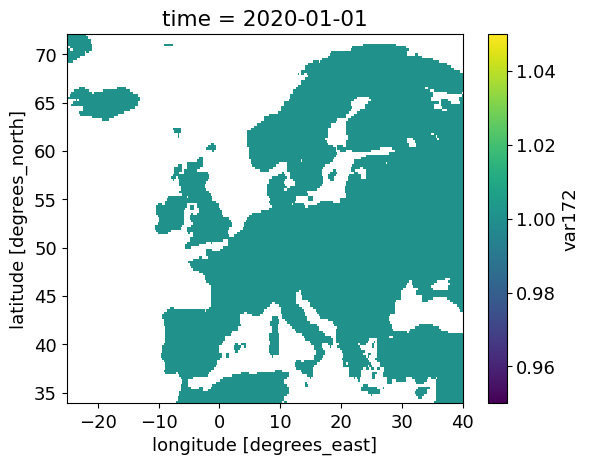

In [138]:
# read landmask
ifile_name    = "landmask_era5_europe.nc"
ifile         = os.path.join("masks", ifile_name)
varname       = "var172"
landmask = xr.open_dataset(ifile)[varname]
landmask = landmask.where( landmask.values == 1 )
landmask.plot()

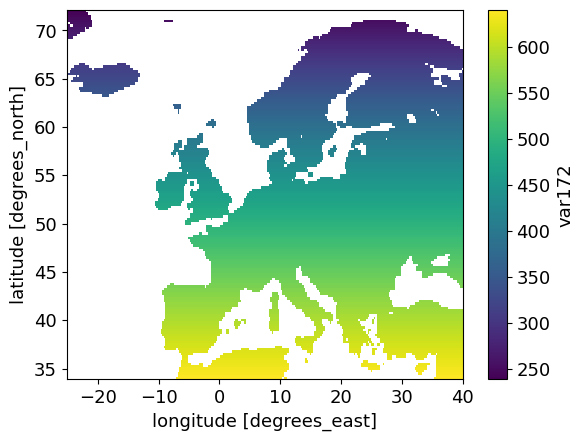

In [139]:
area_2d = calculate_gridarea(landmask.lat, res=abs(landmask.lat[1]-landmask.lat[0]), nlon=len(landmask.lon))*landmask[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': landmask.lat,'lon': landmask.lon}, dims=["lat", "lon"])
area_2d.plot()

12
2023-01
2023
13
2023-02
2023
14
2023-03
2023
15
2023-04
2023
16
2023-05
2023
17
2023-06
2023
18
2023-07
2023
19
2023-08
2023
20
2023-09
2023
21
2023-10
2023
22
2023-11
2023
23
2023-12
2023
24
2024-01
2024


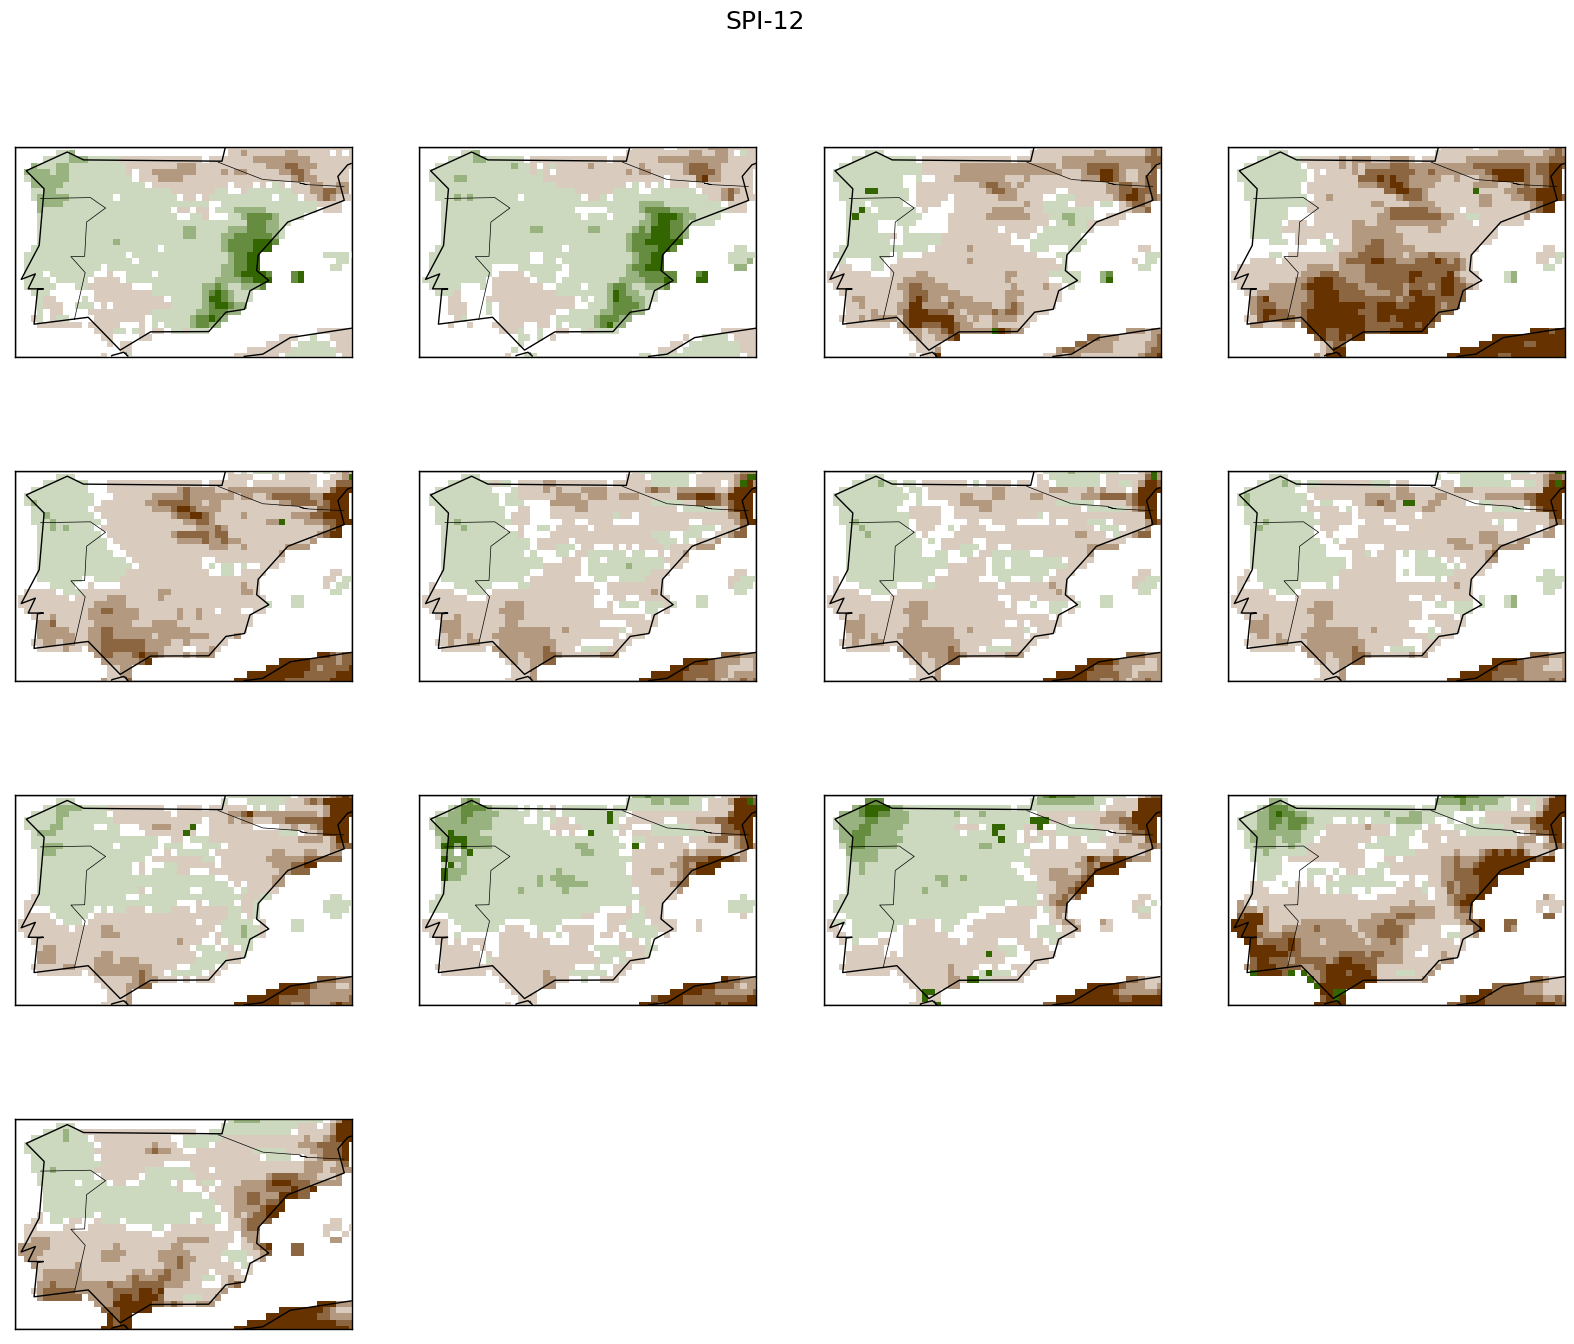

In [140]:
spi12           = xr.open_dataset(os.path.join(ipath, f"SPI12_gamma_{region}_era5t_moda_ref{ref_period}_20220101to20240101.nc"))[f"SPI12"]
spi12           = spi12.where(spi12 != -9999)

# multi-panel plot, iterating through
# https://engineeringfordatascience.com/posts/matplotlib_subplots/

lats = np.asarray(spi12.lat)
lons = np.asarray(spi12.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)

#fig, axs = plt.subplots(4, 4, figsize=(20,16), gridspec_kw={'height_ratios': [ 1.5, 1.5, 1.5, 1.5]})
#fig.suptitle(f"SPI-12", fontsize=18)
plt.figure(figsize=(20, 16))
plt.subplots_adjust(hspace=0.25)
plt.suptitle("SPI-12", fontsize=18, y=0.95)

itrange = range(len(spi12.time))[-13:]

for n, itime in enumerate(itrange):
#for itime, ax in zip(itrange, axs.ravel()):

    ax = plt.subplot(4, 4, n + 1)
    
    print(itime)
    stime = spi12.time.dt.strftime('%Y-%m').values[:][itime]
    print(stime)
    ytime = spi12.time.dt.strftime('%Y').values[:][itime]
    print(ytime)
    
    # adjust limits for plotting
    zlim = [-3,3]
    map_2d = np.asarray(spi12.sel(time=spi12.time[itime]).values[:])
    map_2d[map_2d <= zlim[0]] = zlim[0]
    map_2d[map_2d >= zlim[1]] = zlim[1]

    # basemap
    m = Basemap(projection='cyl', \
                llcrnrlon=-9.75, \
                urcrnrlon=3.5, \
                llcrnrlat=35.75, \
                urcrnrlat=44, \
                resolution='c')
    x, y = m(grid_lon, grid_lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()

    ax = m.pcolormesh(x, y, map_2d, shading='auto', cmap=cmap_spi, norm=clevels_spi)
    #m.set_xlim([-9.75,3.5])
    #ax.set_ylim([35.75,44])
    #ax.title(stime)
    #ax.get_legend().remove()
    #ax.set_xlabel("")
    del(map_2d)

#plt.subplots_adjust(right=0.8)
#cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])
#cbar = fig.colorbar(orientation='vertical', shrink=0.85, cax=cbar_ax)
#ax.cax.colorbar()
#ax.cax.toggle_label(True)
#import matplotlib as mpl
#cax,kw = mpl.colorbar.make_axes([ax for ax in axs.flat])
#cbar = plt.colorbar(cax=cax, **kw)
#cbar = plt.colorbar(orientation='vertical', shrink=0.85, ax=axs.ravel().tolist())
#cbar.ax.set_title('SPI-12 [-]')
#cbar.set_ticks([-3,-2,-1.5,-1,0,1,1.5,2,3])
#cbar.set_ticklabels(["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"])
#axn  = plt.subplot(4, 4, n + 1)
#cbar = plt.colorbar(axs[3,3], orientation='vertical', shrink=0.85)
#cbar.ax.set_title('SPI-12 [-]')
#cbar.set_ticks([-3,-2,-1.5,-1,0,1,1.5,2,3])
#cbar.set_ticklabels(["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"])

plt.savefig("figures/Droughtmaps_Catalunya_SPI-12_series.pdf", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()
    

12
2023-01
2023
13
2023-02
2023
14
2023-03
2023
15
2023-04
2023
16
2023-05
2023
17
2023-06
2023
18
2023-07
2023
19
2023-08
2023
20
2023-09
2023
21
2023-10
2023
22
2023-11
2023
23
2023-12
2023
24
2024-01
2024


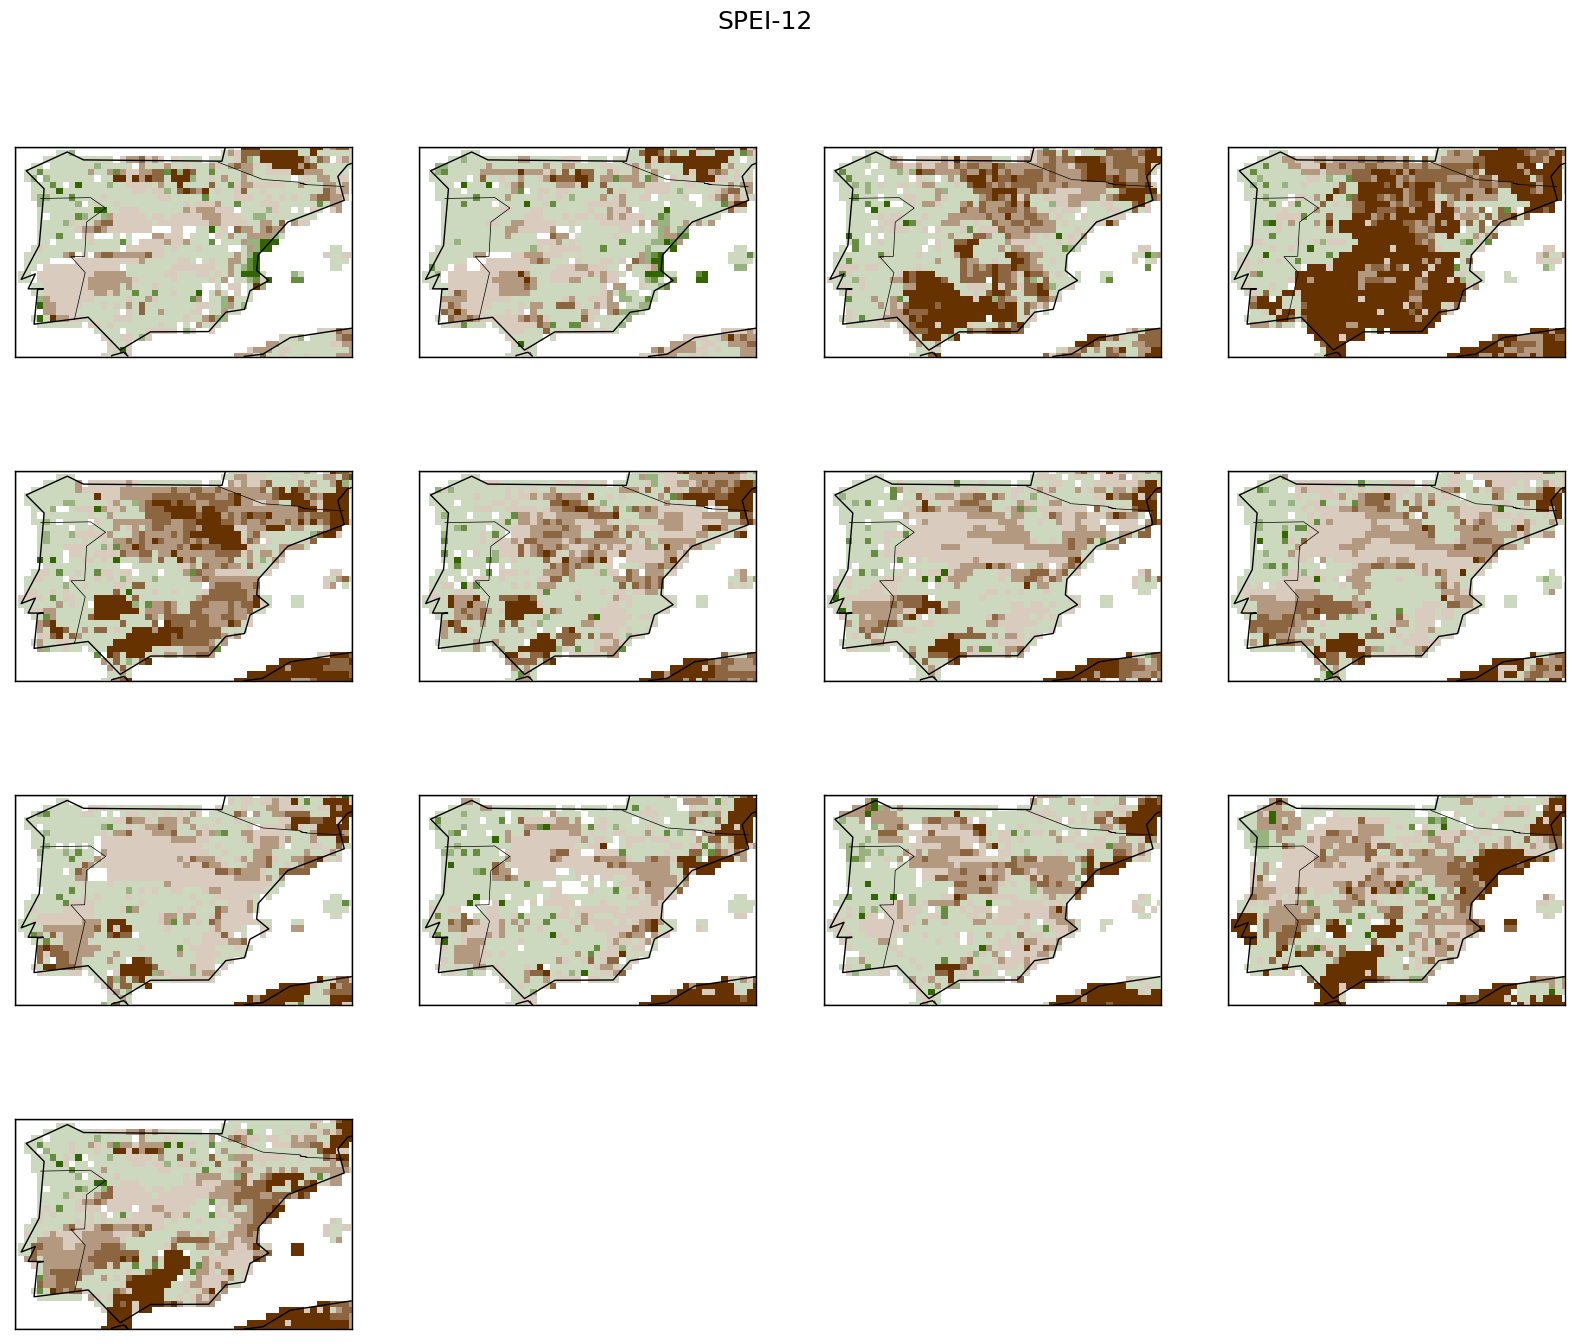

In [141]:
spei12         = xr.open_dataset(os.path.join(ipath, f"SPEI12_genextreme_{region}_era5t_moda_ref{ref_period}_20220101to20240101.nc"))[f"SPEI12"]
spei12         = spei12.where(spei12 != -9999)


# multi-panel plot, iterating through
# https://engineeringfordatascience.com/posts/matplotlib_subplots/

lats = np.asarray(spei12.lat)
lons = np.asarray(spei12.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)


plt.figure(figsize=(20, 16))
plt.subplots_adjust(hspace=0.25)
plt.suptitle("SPEI-12", fontsize=18, y=0.95)

itrange = range(len(spei12.time))[-13:]

for n, itime in enumerate(itrange):
#for itime, ax in zip(itrange, axs.ravel()):

    ax = plt.subplot(4, 4, n + 1)
    
    print(itime)
    stime = spei12.time.dt.strftime('%Y-%m').values[:][itime]
    print(stime)
    ytime = spei12.time.dt.strftime('%Y').values[:][itime]
    print(ytime)
    
    # adjust limits for plotting
    zlim = [-3,3]
    map_2d = np.asarray(spei12.sel(time=spei12.time[itime]).values[:])
    map_2d[map_2d <= zlim[0]] = zlim[0]
    map_2d[map_2d >= zlim[1]] = zlim[1]

    # basemap
    m = Basemap(projection='cyl', \
                llcrnrlon=-9.75, \
                urcrnrlon=3.5, \
                llcrnrlat=35.75, \
                urcrnrlat=44, \
                resolution='c')
    x, y = m(grid_lon, grid_lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()

    ax = m.pcolormesh(x, y, map_2d, shading='auto', cmap=cmap_spei, norm=clevels_spei)
    
    del(map_2d)

plt.savefig("figures/Droughtmaps_Catalunya_SPEI-12_series.pdf", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()
    

996
2023-01
2023
997
2023-02
2023
998
2023-03
2023
999
2023-04
2023
1000
2023-05
2023
1001
2023-06
2023
1002
2023-07
2023
1003
2023-08
2023
1004
2023-09
2023
1005
2023-10
2023
1006
2023-11
2023
1007
2023-12
2023
1008
2024-01
2024


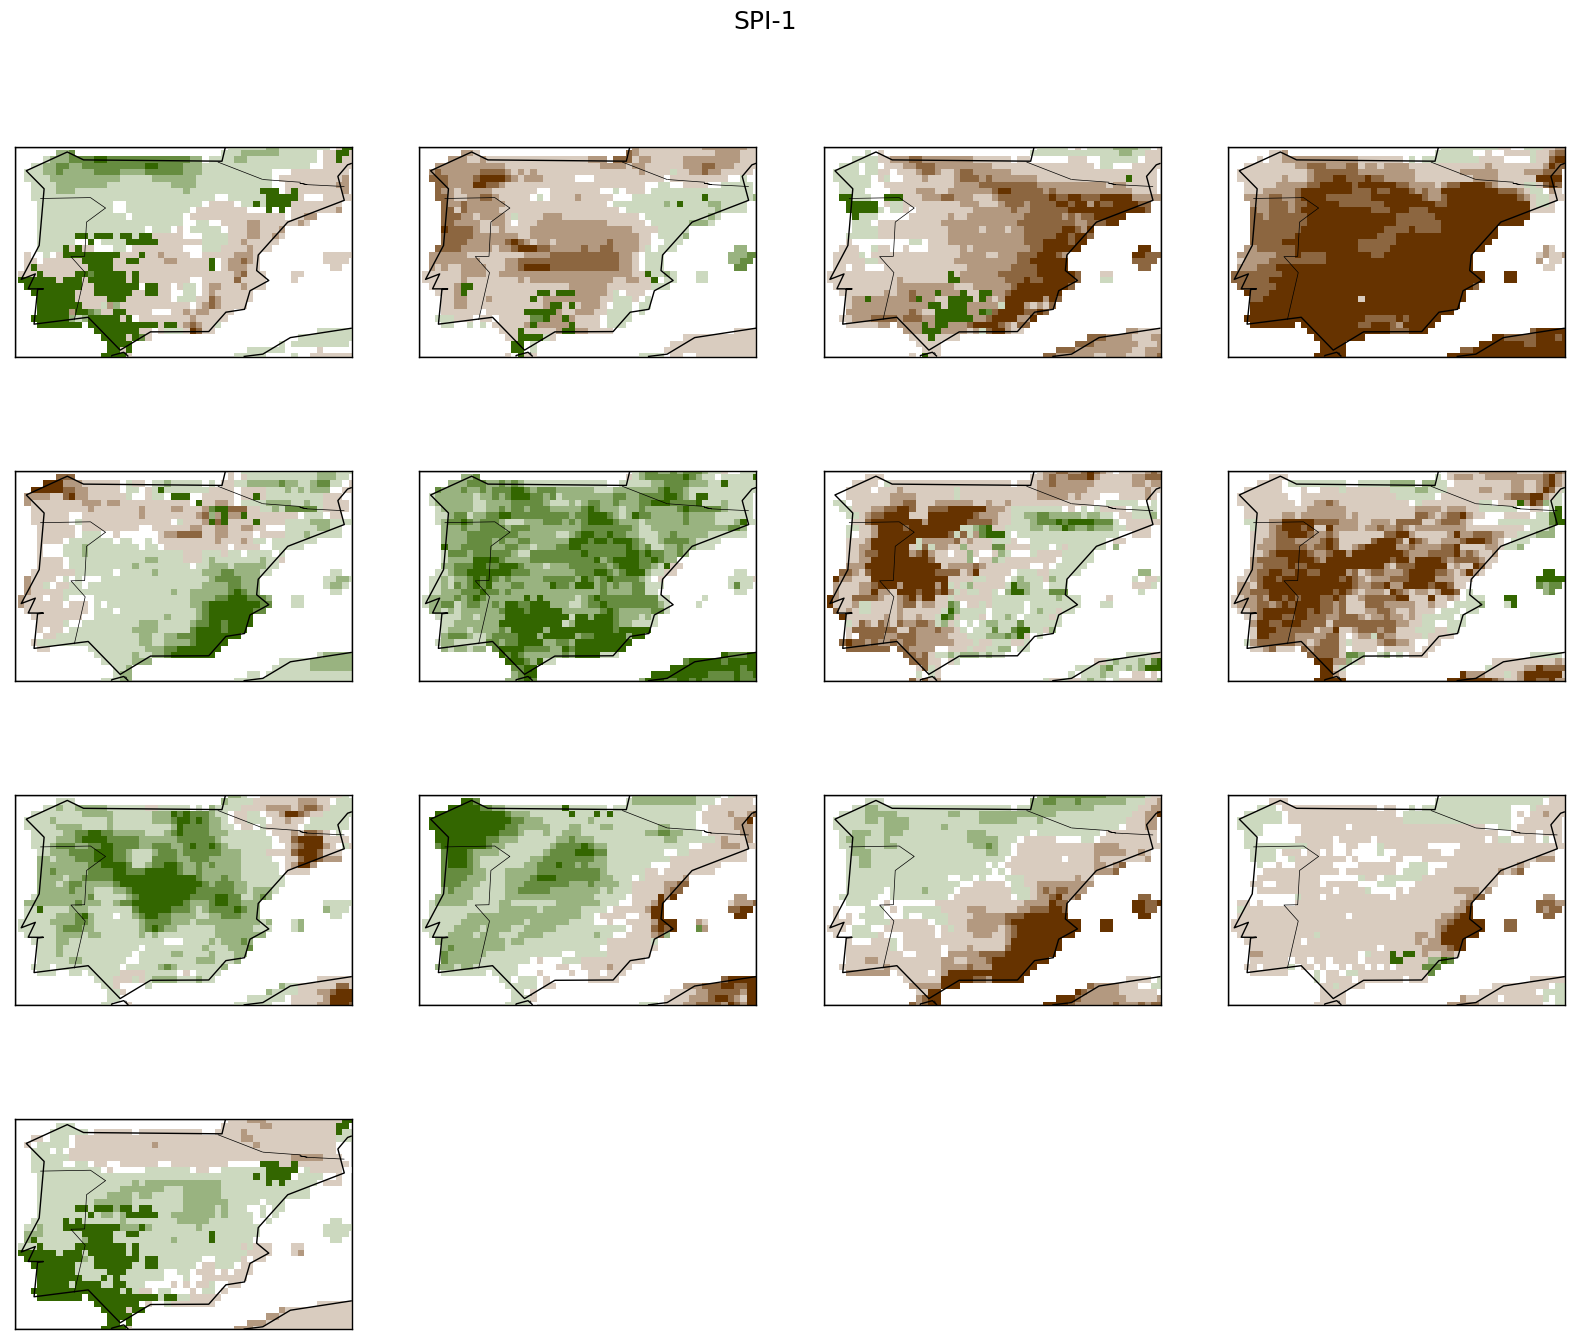

In [142]:
spi1          = xr.open_dataset(os.path.join(ipath, f"SPI1_gamma_{region}_era5t_moda_ref{ref_period}_19400101to20240101.nc"))[f"SPI1"]
spi1          = spi1.where(spi1 != -9999)

# multi-panel plot, iterating through
# https://engineeringfordatascience.com/posts/matplotlib_subplots/

lats = np.asarray(spi1.lat)
lons = np.asarray(spi1.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)

plt.figure(figsize=(20, 16))
plt.subplots_adjust(hspace=0.25)
plt.suptitle("SPI-1", fontsize=18, y=0.95)

itrange = range(len(spi1.time))[-13:]

for n, itime in enumerate(itrange):
#for itime, ax in zip(itrange, axs.ravel()):

    ax = plt.subplot(4, 4, n + 1)
    
    print(itime)
    stime = spi1.time.dt.strftime('%Y-%m').values[:][itime]
    print(stime)
    ytime = spi1.time.dt.strftime('%Y').values[:][itime]
    print(ytime)
    
    # adjust limits for plotting
    zlim = [-3,3]
    map_2d = np.asarray(spi1.sel(time=spi1.time[itime]).values[:])
    map_2d[map_2d <= zlim[0]] = zlim[0]
    map_2d[map_2d >= zlim[1]] = zlim[1]

    # basemap
    m = Basemap(projection='cyl', \
                llcrnrlon=-9.75, \
                urcrnrlon=3.5, \
                llcrnrlat=35.75, \
                urcrnrlat=44, \
                resolution='c')
    x, y = m(grid_lon, grid_lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()

    ax = m.pcolormesh(x, y, map_2d, shading='auto', cmap=cmap_spi, norm=clevels_spi)
    
    del(map_2d)
    
plt.savefig("figures/Droughtmaps_Catalunya_SPI-1_series.pdf", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()
    

Processing SPEI-12...
2023-11
2023


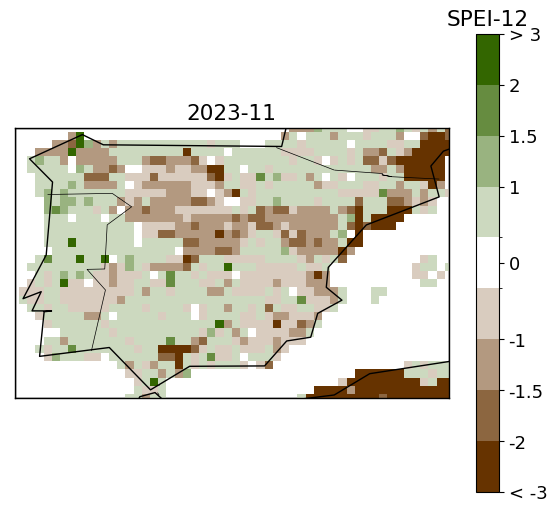

Processing SPEI-12...
2023-12
2023


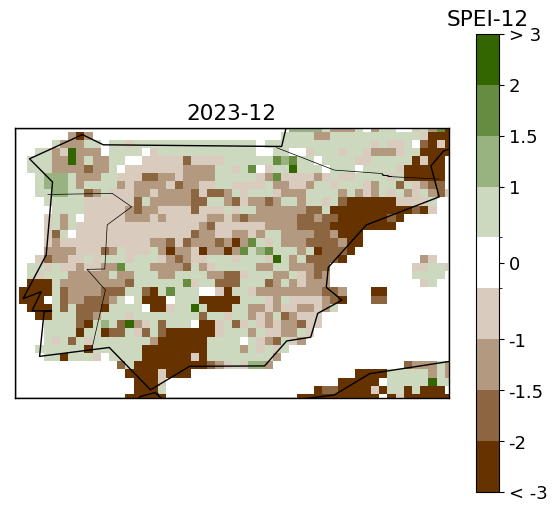

Processing SPEI-12...
2024-01
2024


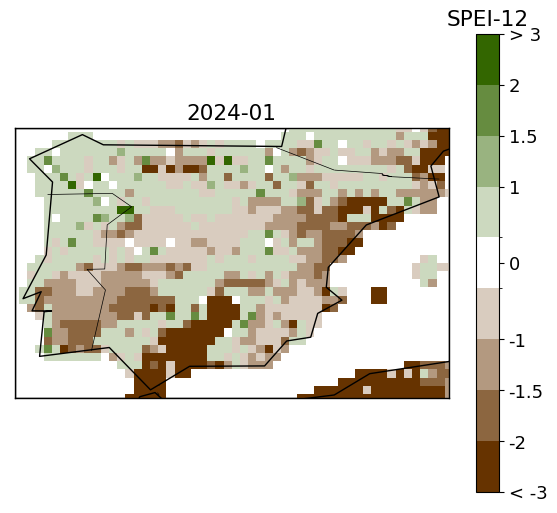

Processing SPI-12...


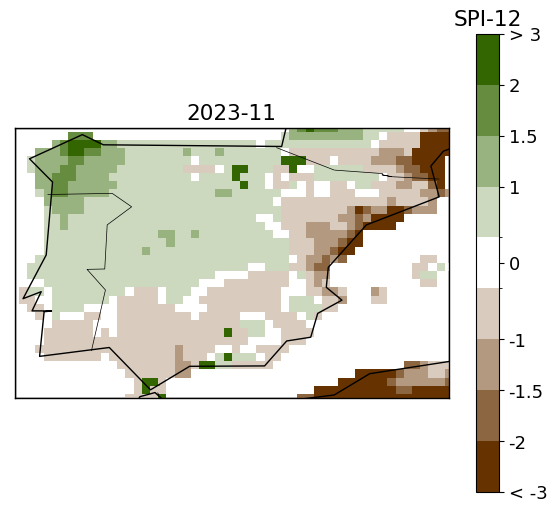

Processing SPI-12...


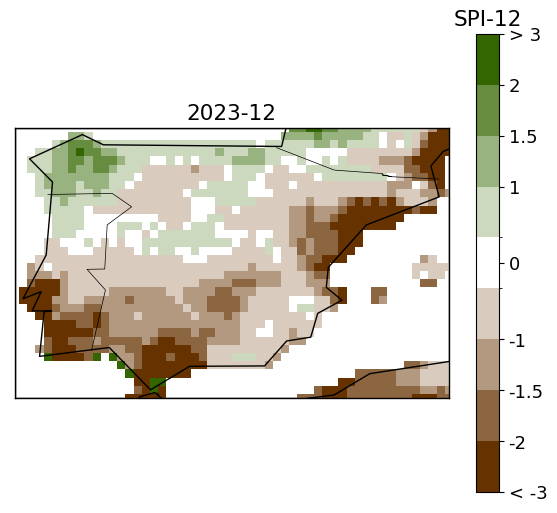

Processing SPI-12...


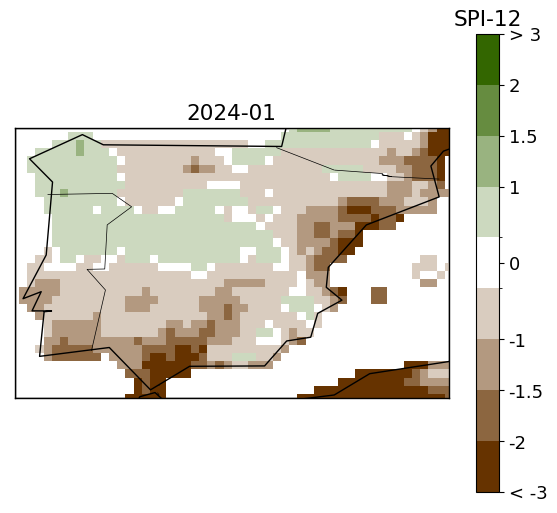

In [143]:
lats = np.asarray(spi12.lat)
lons = np.asarray(spi12.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)
    
for itime in range(len(spei12.time))[-3:]:

    print(f"Processing SPEI-12...")

    stime = spei12.time.dt.strftime('%Y-%m').values[:][itime]
    print(stime)
    ytime = spei12.time.dt.strftime('%Y').values[:][itime]
    print(ytime)

    # plot
    figname = f"figures/Droughtmap_Catalunya_SPEI-12_{stime}.png"
    to_plot = np.asarray(spei12.sel(time=spei12.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-9.75,3.5], ylim=[35.75,44], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPEI-12", 
                    colorscheme=cmap_spei, levels=clevels_spei, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

for itime in range(len(spi12.time))[-3:]:

    print(f"Processing SPI-12...")

    stime = spi12.time.dt.strftime('%Y-%m').values[:][itime]
    ytime = spi12.time.dt.strftime('%Y').values[:][itime]

    # plot
    figname = f"figures/Droughtmap_Catalunya_SPI-12_{stime}.pdf"
    to_plot = np.asarray(spi12.sel(time=spi12.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-9.75,3.5], ylim=[35.75,44], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPI-12", 
                    colorscheme=cmap_spi, levels=clevels_spi, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

    

## Some timeseries for Spain...

In [144]:
from helpers.geodata import mask_gridpoints_in_polygon, grid2df

In [145]:
# grid to work with
lats           = np.asarray(spi1.lat)
lons           = np.asarray(spi1.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)
gpoints        = grid2df(grid_lon, grid_lat, ret='gpd', crs='epsg:4326')

In [146]:
#regionmask.defined_regions.natural_earth.countries_110['Spain','Portugal'].plot()
#(regionmask.defined_regions.natural_earth.countries_110['Spain','Portugal']).mask(spi12.lon.values[:], spi12.lat.values[::-1])
#ModuleNotFoundError: No module named 'shapely.vectorized._vectorized'

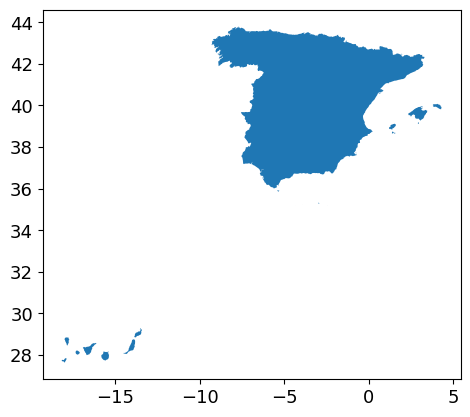

In [147]:
# Country to be selected
country = ["Spain"]
country_name = 'Spain'
geoshp = gpd.read_file('regions/ne_10m_admin_0_countries_lakes') 
countryshpa = geoshp.loc[ (geoshp.ADMIN.isin(country)), 'geometry' ]
countryshpa.plot()
countryshp = countryshpa.unary_union

In [148]:
# get mask of grid points in countryshp
countrymask    = mask_gridpoints_in_polygon(gpoints, countryshp, return_shape=grid_lon.shape, crs='epsg:4326')
print((countrymask == 1).any())
print(len(np.where(countrymask==1)[0]))
print(countrymask.shape)
countrymask_xr = xr.DataArray(countrymask, coords={'lat': lats, 'lon': lons}, dims=["lat", "lon"])
countrymask_xr = countrymask_xr.where( countrymask_xr.values == 1 ) # to get nan in all other cases, 0 otherwise
print(countrymask_xr)
countrymask_3d_xr = countrymask_xr.expand_dims(dim={"time": spi1.time}, axis=0)
print(countrymask_3d_xr.shape)

True
848
(153, 261)
<xarray.DataArray (lat: 153, lon: 261)>
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])
Coordinates:
  * lat      (lat) float64 72.0 71.75 71.5 71.25 71.0 ... 34.75 34.5 34.25 34.0
  * lon      (lon) float64 -25.0 -24.75 -24.5 -24.25 ... 39.25 39.5 39.75 40.0
(1009, 153, 261)


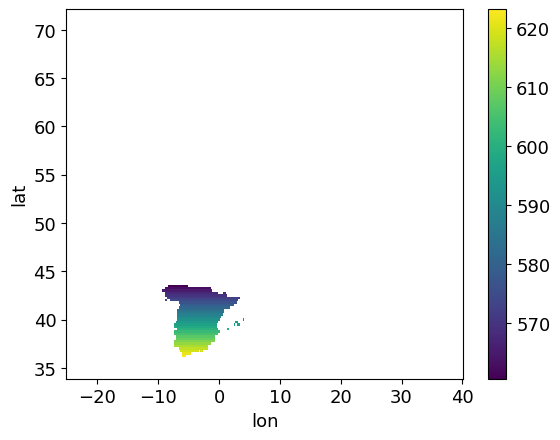

In [149]:
area_2d = calculate_gridarea(countrymask_xr.lat, res=abs(countrymask_xr.lat[1]-countrymask_xr.lat[0]), nlon=len(countrymask_xr.lon))*countrymask_xr.values[:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': countrymask_xr.lat,'lon': countrymask_xr.lon}, dims=["lat", "lon"])
area_2d.plot()
area_3d     = area_2d.expand_dims(dim={"time": spi1.time}, axis=0)
#area_3d.isel(time=10).plot()

In [150]:
aid_spi1   = {}

for severity in ['mild','moderate','severe','extreme','any']:

    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = 0
        
    # SPI-1
    rspi   = spi1*countrymask_3d_xr
    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    aid_spi1[severity] = tmp
    del(tmp, rspi, dmask)
    


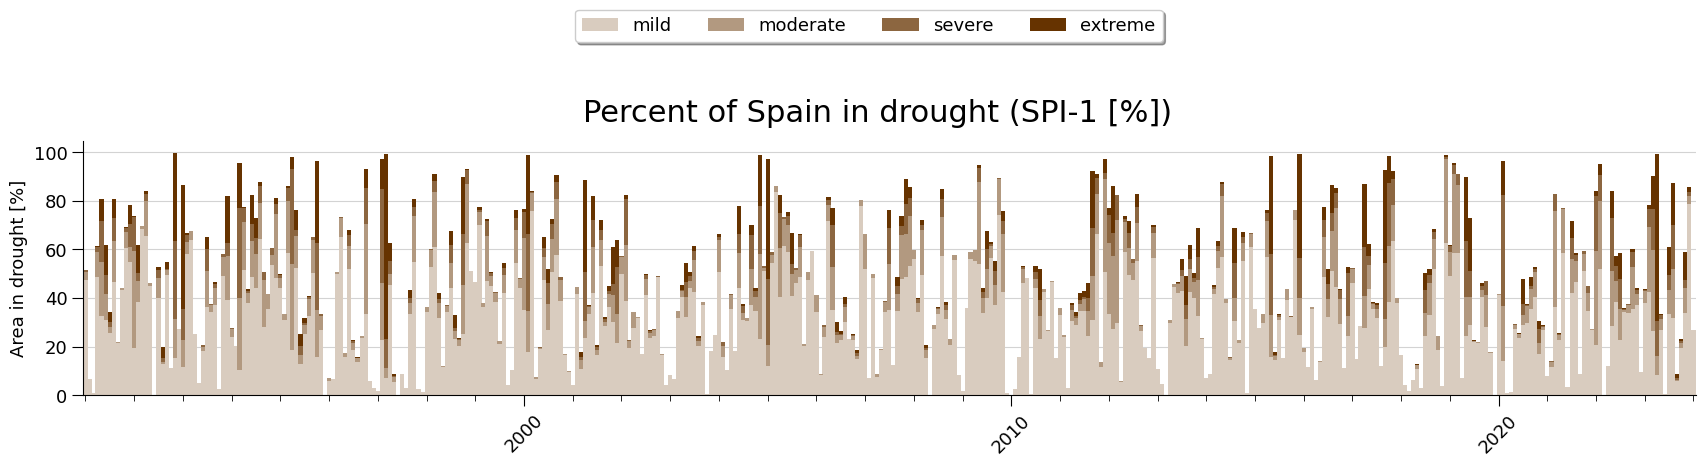

In [151]:
fig, ax1 = plt.subplots(1,1, figsize=(18,4))
fig.suptitle(f"Percent of Spain in drought (SPI-1 [%])", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 13}

plt.rc('font', **font)

severities = ['mild','moderate','severe','extreme']

# single month data
#imonth = 1
#pidata1 = aid_spi1['mild'].sel(time=aid_spi1['mild'].time.dt.month.isin([imonth])).to_series()
#pidata2 = aid_spi1['moderate'].sel(time=aid_spi1['moderate'].time.dt.month.isin([imonth])).to_series()
#pidata3 = aid_spi1['severe'].sel(time=aid_spi1['severe'].time.dt.month.isin([imonth])).to_series()
#pidata4 = aid_spi1['extreme'].sel(time=aid_spi1['extreme'].time.dt.month.isin([imonth])).to_series()

yyyystart = 1990
pidata1 = aid_spi1['mild'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
pidata2 = aid_spi1['moderate'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
pidata3 = aid_spi1['severe'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
pidata4 = aid_spi1['extreme'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
#apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=1), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax1.set_ylabel("Area in drought [%]")
ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
#ax1.spines['bottom'].set_visible(False)
#ax1.spines['left'].set_visible(False)  
#ax1.tick_params(axis='both', colors='dimgrey')
#ax1.xaxis.label.set_color('dimgrey')
#ax1.yaxis.label.set_color('dimgrey')
#ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
ax1.xaxis.set_minor_locator(mdates.YearLocator())
ax1.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax1.xaxis.set_major_formatter(date_form)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=8)
#ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    

## Timeseries for Catalunya...

In [152]:
# grid to work with
lats           = np.asarray(spi1.lat)
lons           = np.asarray(spi1.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)
gpoints        = grid2df(grid_lon, grid_lat, ret='gpd', crs='epsg:4326')

In [153]:
# NUTS region to be selected
#country = ["Spain"]
#country_name = 'Spain'
#geoshp = gpd.read_file('regions/NUTS_RG_20M_2021_4326') 
#print(geoshp.head())
#geoshp = gpd.read_file('regions/NUTS_RG_20M_2021_4326', where="NUTS_NAME='España'") 
#countryshpa = geoshp.loc[ (geoshp.properties.NUTS_NAME.isin(country)), 'geometry' ]
#print(geoshp.explode)

#countryshpa.plot()
#countryshp = countryshpa.unary_union

{'geometry': 'Polygon',
 'properties': OrderedDict([('NUTS_ID', 'str:5'),
                            ('LEVL_CODE', 'int:1'),
                            ('CNTR_CODE', 'str:2'),
                            ('NAME_LATN', 'str:70'),
                            ('NUTS_NAME', 'str:106'),
                            ('MOUNT_TYPE', 'int:1'),
                            ('URBN_TYPE', 'int:1'),
                            ('COAST_TYPE', 'int:1'),
                            ('FID', 'str:5')])}
{'driver': 'ESRI Shapefile', 'schema': {'properties': OrderedDict([('NUTS_ID', 'str:5'), ('LEVL_CODE', 'int:1'), ('CNTR_CODE', 'str:2'), ('NAME_LATN', 'str:70'), ('NUTS_NAME', 'str:106'), ('MOUNT_TYPE', 'int:1'), ('URBN_TYPE', 'int:1'), ('COAST_TYPE', 'int:1'), ('FID', 'str:5')]), 'geometry': 'Polygon'}, 'crs': {'init': 'epsg:4326'}, 'crs_wkt': 'GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG

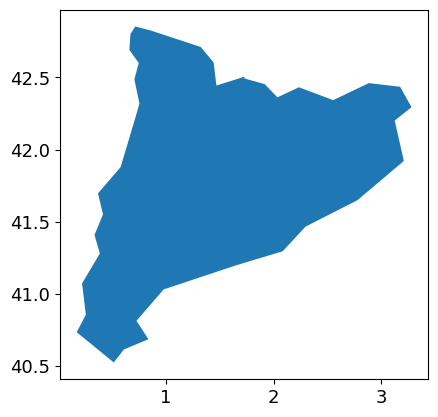

In [154]:
nutsshp = "/home/nejk/code/drought_on_demand/regions/NUTS_RG_20M_2021_4326/NUTS_RG_20M_2021_4326.shp"
import fiona
from shapely.geometry import shape
# Open the shapefile
shapefile = fiona.open(nutsshp)
import pprint
pprint.pprint(shapefile.schema)
print(shapefile.meta)
#for record in shapefile:
#    print(shape(record['properties'].get('NUTS_NAME')))
for feature in shapefile:
    #if ("ES51" in feature['properties']['FID']):
    if (feature['properties']['FID'] == "ES51"):
        print(feature['properties']['NUTS_ID'])
        print(feature['properties']['LEVL_CODE'])
        print(feature['properties']['NUTS_NAME'])
        print(feature['properties']['NAME_LATN'])
        catalunya = feature
        with fiona.open('regions/catalunya.shp', 'w', **shapefile.meta) as output:
            output.write(feature)
    #if ("España" in feature['properties']['NUTS_NAME']):
    #    print(feature['properties']['NUTS_ID'])
    #    print(feature['properties']['LEVL_CODE'])
    #    print(feature['properties']['NUTS_NAME'])
    #    print(feature['properties']['NAME_LATN'])
    #    spain = feature
print(type(catalunya))
print((catalunya))

geoshp = gpd.read_file('regions/catalunya.shp')
print(type(geoshp))
print(geoshp.head())
#geoshp = gpd.read_file('regions/NUTS_RG_20M_2021_4326', where="NUTS_NAME='España'") 
countryshpa = geoshp.loc[ (geoshp.FID == 'ES51'), 'geometry' ]
#print(geoshp.explode)

countryshpa.plot()
print(countryshpa.geometry)
countryshpa=countryshpa.to_crs('epsg:4326')
gpoints=gpoints.set_crs('epsg:4326')
#countryshp = countryshpa.unary_union
#filtered = filter(lambda f: f['properties']['NUTS_NAME']=='Spain', shapefile)
#print(filtered)
#for record in shapefile:
#    # Get the geometry from the record
#    geometry = shape(record.meta['properties']['NUTS_NAME'])
#    # Print the area of the geometry
#    print(geometry)

0    LINEARRING (1.44257 42.60367, 1.46852 42.44399...
dtype: geometry
<class 'geopandas.geodataframe.GeoDataFrame'>
False
(153, 261)


/usr/local/apps/python3/3.10.10-01/lib/python3.10/site-packages/geopandas/base.py:31: UserWarning: The indices of the two GeoSeries are different.
  warn("The indices of the two GeoSeries are different.")


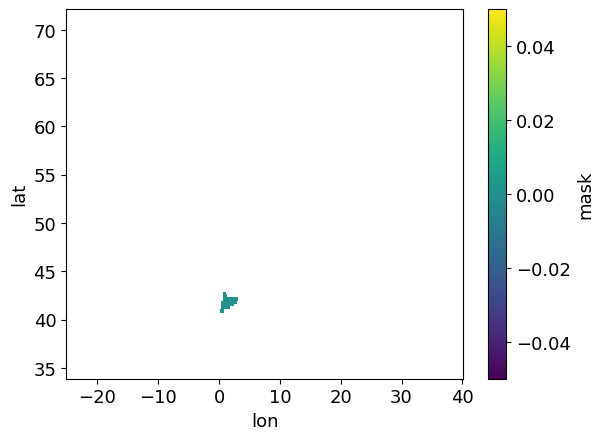

In [155]:
# get mask of grid points in countryshp
#countrymask    = mask_gridpoints_in_polygon(gpoints, countryshpa.geometry, return_shape=grid_lon.shape, crs='epsg:4326')
print(((geoshp['geometry']).exterior))
print(type(gpoints))
gpinside       = geoshp['geometry'].exterior.contains(gpoints)
print((gpinside == True).any())
#gpinside = gpd.sjoin(gpoints, geoshp, how='inner', op='intersects')
#print(gpinside)
#print(type(gpinside))
#countrymask = np.zeros(shape=(grid_lon.shape))
#countrymask = xr.DataArray(np.zeros(shape=(grid_lon.shape)), coords={'lat': lats, 'lon': lons}, dims=["lat", "lon"])


#ax = geoshp.plot(alpha=0.2, color='black')
#spi12.mean(dim="time").plot(ax=ax,zorder=-1)

import regionmask
nutsmask = regionmask.mask_geopandas(geoshp, lons, lats)
print(nutsmask.shape)
nutsmask.plot()
#geodf = geopandas.read_file(...)
#xds = rioxarray.open_rasterio(os.path.join(ipath, f"SPEI12_genextreme_{region}_era5t_moda_ref{ref_period}_20220101to20240101.nc"))
#clipped = xds.rio.clip(geoshp.geometry)

True
848
(153, 261)
<xarray.DataArray (lat: 153, lon: 261)>
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]])
Coordinates:
  * lat      (lat) float64 72.0 71.75 71.5 71.25 71.0 ... 34.75 34.5 34.25 34.0
  * lon      (lon) float64 -25.0 -24.75 -24.5 -24.25 ... 39.25 39.5 39.75 40.0
(1009, 153, 261)


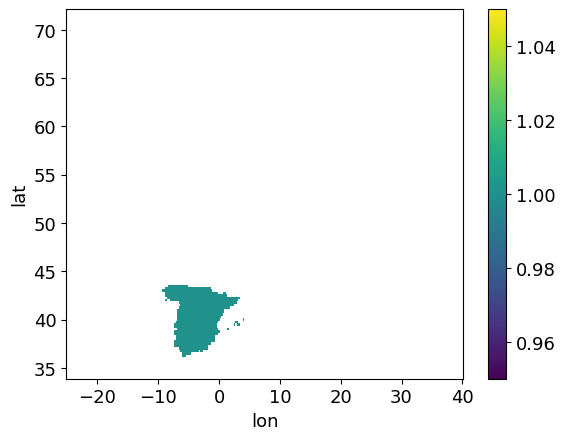

In [156]:

print((countrymask == 1).any())
print(len(np.where(countrymask==1)[0]))
print(countrymask.shape)
countrymask_xr = xr.DataArray(countrymask, coords={'lat': lats, 'lon': lons}, dims=["lat", "lon"])
countrymask_xr = countrymask_xr.where( countrymask_xr.values == 1 ) # to get nan in all other cases, 0 otherwise
print(countrymask_xr)
countrymask_xr.plot()
countrymask_3d_xr = countrymask_xr.expand_dims(dim={"time": spi1.time}, axis=0)
print(countrymask_3d_xr.shape)

996
2023-01
2023
997
2023-02
2023
998
2023-03
2023
999
2023-04
2023
1000
2023-05
2023
1001
2023-06
2023
1002
2023-07
2023
1003
2023-08
2023
1004
2023-09
2023
1005
2023-10
2023
1006
2023-11
2023
1007
2023-12
2023
1008
2024-01
2024


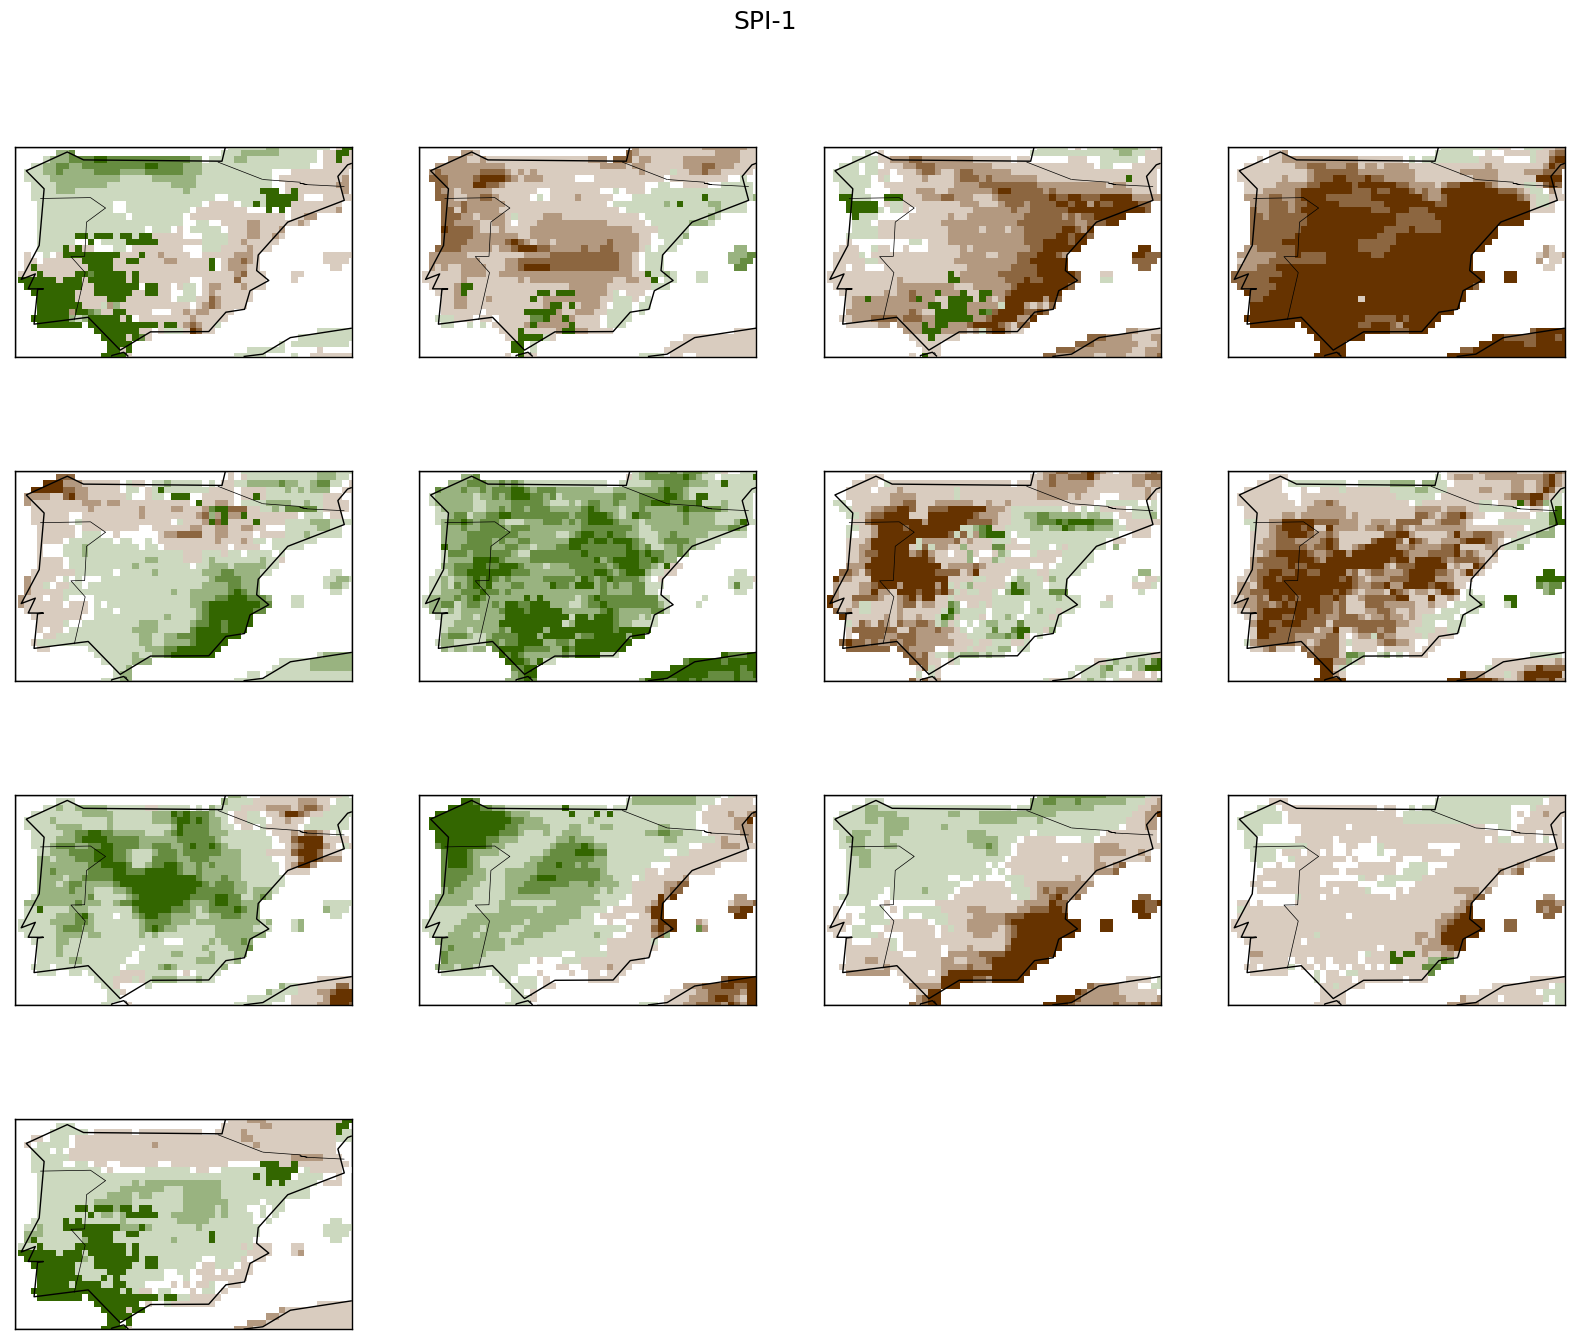

In [157]:
spi1          = xr.open_dataset(os.path.join(ipath, f"SPI1_gamma_{region}_era5t_moda_ref{ref_period}_19400101to20240101.nc"))[f"SPI1"]
spi1          = spi1.where(spi1 != -9999)

# multi-panel plot, iterating through
# https://engineeringfordatascience.com/posts/matplotlib_subplots/

lats = np.asarray(spi1.lat)
lons = np.asarray(spi1.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)

plt.figure(figsize=(20, 16))
plt.subplots_adjust(hspace=0.25)
plt.suptitle("SPI-1", fontsize=18, y=0.95)

itrange = range(len(spi1.time))[-13:]

for n, itime in enumerate(itrange):
#for itime, ax in zip(itrange, axs.ravel()):

    ax = plt.subplot(4, 4, n + 1)
    
    print(itime)
    stime = spi1.time.dt.strftime('%Y-%m').values[:][itime]
    print(stime)
    ytime = spi1.time.dt.strftime('%Y').values[:][itime]
    print(ytime)
    
    # adjust limits for plotting
    zlim = [-3,3]
    map_2d = np.asarray(spi1.sel(time=spi1.time[itime]).values[:])
    map_2d[map_2d <= zlim[0]] = zlim[0]
    map_2d[map_2d >= zlim[1]] = zlim[1]

    # basemap
    m = Basemap(projection='cyl', \
                llcrnrlon=-9.75, \
                urcrnrlon=3.5, \
                llcrnrlat=35.75, \
                urcrnrlat=44, \
                resolution='c')
    x, y = m(grid_lon, grid_lat)
    m.drawcoastlines()
    m.drawmapboundary()
    m.drawcountries()
    #m.readshapefile('regions/catalunya', 'ES51', drawbounds=True, linewidth=2, color='b')

    ax = m.pcolormesh(x, y, map_2d, shading='auto', cmap=cmap_spi, norm=clevels_spi)
    
    del(map_2d)
    
#plt.savefig("figures/Droughtmaps_Catalunya_SPI-1_series.png", dpi='figure', format=None, metadata=None,
#            bbox_inches=None, pad_inches=0.1,
#            facecolor='auto', edgecolor='auto',
#            backend=None)
plt.show()
    

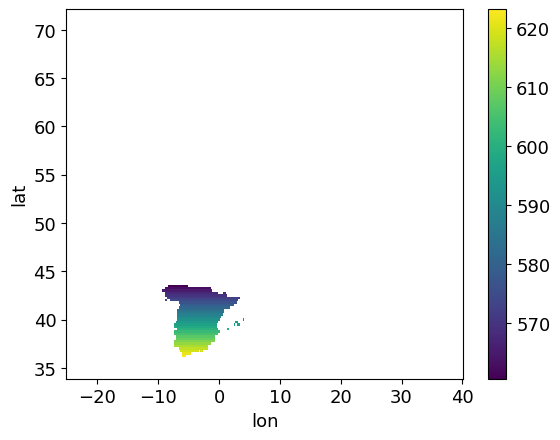

In [158]:
area_2d = calculate_gridarea(countrymask_xr.lat, res=abs(countrymask_xr.lat[1]-countrymask_xr.lat[0]), nlon=len(countrymask_xr.lon))*countrymask_xr.values[:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': countrymask_xr.lat,'lon': countrymask_xr.lon}, dims=["lat", "lon"])
area_2d.plot()
area_3d     = area_2d.expand_dims(dim={"time": spi1.time}, axis=0)
#area_3d.isel(time=10).plot()

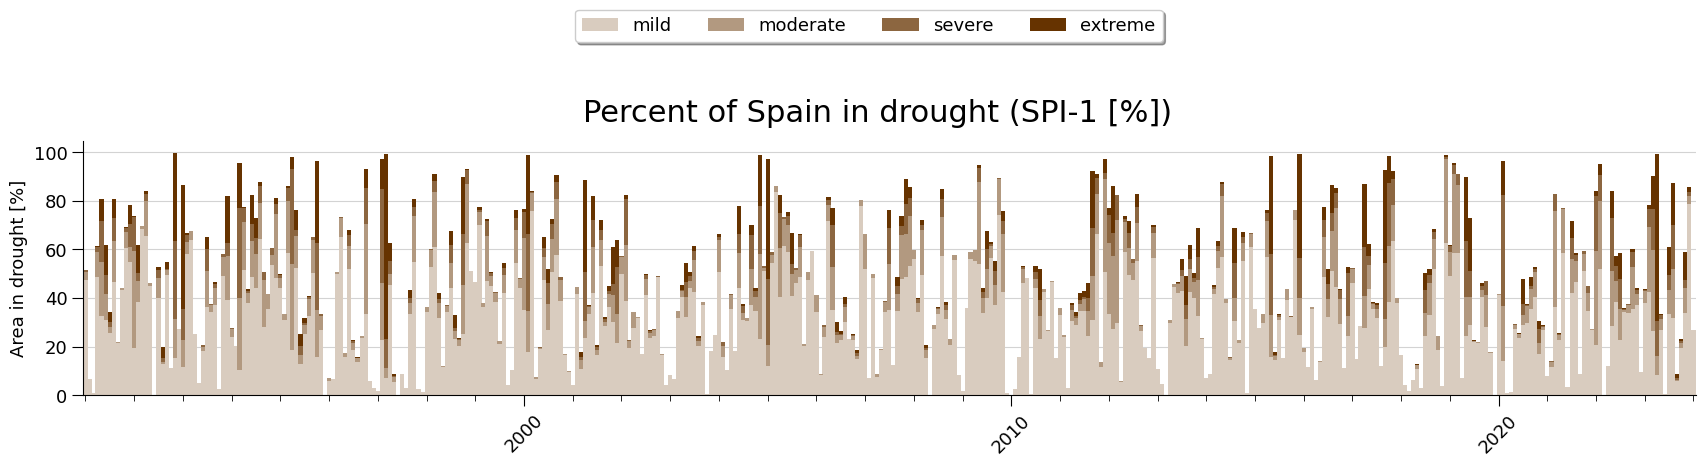

In [161]:
fig, ax1 = plt.subplots(1,1, figsize=(18,4))
fig.suptitle(f"Percent of Spain in drought (SPI-1 [%])", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 13}

plt.rc('font', **font)

severities = ['mild','moderate','severe','extreme']

# single month data
#imonth = 1
#pidata1 = aid_spi1['mild'].sel(time=aid_spi1['mild'].time.dt.month.isin([imonth])).to_series()
#pidata2 = aid_spi1['moderate'].sel(time=aid_spi1['moderate'].time.dt.month.isin([imonth])).to_series()
#pidata3 = aid_spi1['severe'].sel(time=aid_spi1['severe'].time.dt.month.isin([imonth])).to_series()
#pidata4 = aid_spi1['extreme'].sel(time=aid_spi1['extreme'].time.dt.month.isin([imonth])).to_series()

yyyystart = 1990
pidata1 = aid_spi1['mild'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
pidata2 = aid_spi1['moderate'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
pidata3 = aid_spi1['severe'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
pidata4 = aid_spi1['extreme'].sel(time=aid_spi1['mild'].time.dt.year>yyyystart).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
#apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=1), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax1.set_ylabel("Area in drought [%]")
ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
#ax1.spines['bottom'].set_visible(False)
#ax1.spines['left'].set_visible(False)  
#ax1.tick_params(axis='both', colors='dimgrey')
#ax1.xaxis.label.set_color('dimgrey')
#ax1.yaxis.label.set_color('dimgrey')
#ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
ax1.xaxis.set_minor_locator(mdates.YearLocator())
ax1.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax1.xaxis.set_major_formatter(date_form)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=8)
#ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    

In [160]:
#from shapely.geometry import mapping, shape
from fiona import collection

with collection(nutsshp, "r") as input:
    #schema = input.schema.copy()
    schema = { 'geometry': 'Polygon', 'properties': { 'NUTS_NAME': 'str' } }
    i = 0
    with collection(
        "some_buffer.shp", "w", "ESRI Shapefile", schema) as output:
        for point in input:
            if ("España" in point['properties']['NUTS_NAME']):
                print(i)
                output.write({
                    'properties': {
                        'NUTS_NAME': point['properties']['NUTS_NAME']
                    },
                    'geometry': mapping(shape(point['geometry']).buffer(1.0))
                })
            i += 1

23


In [ ]:
#open your shapefile and xarray object
gdf = gpd.read_file("some_buffer.shp")

#convert the geometry of a single polygon in your gdf (adjust the index, [0], to match the row of the dataframe you care about)
#geom = geometry.Geometry(
#            gdf.geometry.values[0].__geo_interface__, geometry.CRS(
#                'epsg:4326'))
import 
# create polygon mask
mask = rasterio.features.geometry_mask(
            [geom.to_crs(ds.geobox.crs) for geoms in [spain]],
            out_shape=ds.geobox.shape,
            transform=ds.geobox.affine,
            all_touched=False,
            invert=False)

mask = xr.DataArray(mask, dims=("y", "x"))

#mask ds with rasterized gdf
#ds = ds.where(mask == False)

In [ ]:
area_3d     = area_2d.sel(lon=slice(-9.75,3.5),lat=slice(44,35.75)).expand_dims(dim={"time": subregion_spei12.time}, axis=0)
landmask_3d = landmask.sel(lon=slice(-9.75,3.5),lat=slice(44,35.75)).reindex_like(spei12, method='nearest')
#to_plot = subregions_landarea['Southwestern Europe'].reindex_like(spi3, method="nearest")
#to_plot.sel(time="2020-08-01").plot()
#print(to_plot.sum(dim=['lat','lon']))

In [ ]:
#area_2d.sel(lon=slice(-9.5,3.5),lat=slice(35,44)).plot()
landmask.sel(lon=slice(-9.75,3.5),lat=slice(44,35.75)).plot()

In [ ]:
subregion_spei12.shape

In [ ]:
aid_spi1   = {}
aid_spi12  = {}
aid_spei1  = {}
aid_spei12 = {}

for severity in ['mild','moderate','severe','extreme','any']:

    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = 0

    #print(subregions_landarea[iregion].sum(dim=["lat", "lon"]))
    #print(subregions_landarea[iregion].reindex_like(spi3, method="nearest").sum(dim=["lat", "lon"]))

    # SPI
    #rspi   = subregion_spi1*landmask_3d
    #dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    #tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    #aid_spi1[severity] = tmp
    #del(tmp, rspi, dmask)
    
    rspi   = subregion_spi12*landmask_3d
    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    aid_spi12[severity] = tmp
    del(tmp, rspi, dmask)
    
    
    # SPEI
    #rspi   = subregion_spei1*landmask_3d
    #dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    #tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    #aid_spei1[severity] = tmp
    #del(tmp, rspi, dmask)
    
    rspi   = subregion_spei12*landmask_3d
    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
    tmp    = 100 * (dmask*area_3d).sum(dim=["lat", "lon"]) / area_3d.sum(dim=["lat", "lon"])
    aid_spei12[severity] = tmp
    del(tmp, rspi, dmask)
    


In [ ]:
aid_spei12

In [ ]:
fig, ax1 = plt.subplots(1,1, figsize=(18,4))
fig.suptitle(f"Percent of the Iberian Peninsula in drought (SPEI-12 on 1 Feb, [%])", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 13}

plt.rc('font', **font)

severities = ['mild','moderate','severe','extreme']

imonth = 1

pidata1 = aid_spei12['mild'].sel(time=aid_spei12['mild'].time.dt.month.isin([imonth])).to_series()
pidata2 = aid_spei12['moderate'].sel(time=aid_spei12['moderate'].time.dt.month.isin([imonth])).to_series()
pidata3 = aid_spei12['severe'].sel(time=aid_spei12['severe'].time.dt.month.isin([imonth])).to_series()
pidata4 = aid_spei12['extreme'].sel(time=aid_spei12['extreme'].time.dt.month.isin([imonth])).to_series()
apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
bottom = np.zeros(len(apidata.index))
for i in apidata.columns:
    p = ax1.bar(apidata[i].index, apidata[i].values, width=relativedelta.relativedelta(months=12), facecolor=color_list[3-i], alpha=1, label=severities[i], bottom=bottom)
    bottom += apidata[i].values
ax1.set_ylabel("Area in drought [%]")
ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
#ax1.spines['bottom'].set_visible(False)
#ax1.spines['left'].set_visible(False)  
#ax1.tick_params(axis='both', colors='dimgrey')
#ax1.xaxis.label.set_color('dimgrey')
#ax1.yaxis.label.set_color('dimgrey')
#ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
ax1.xaxis.set_minor_locator(mdates.YearLocator())
ax1.xaxis.set_major_locator(mdates.YearLocator(10))
date_form = DateFormatter("%Y")
ax1.xaxis.set_major_formatter(date_form)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=8)
#ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    

In [ ]:
imonth=1
with pd.option_context('display.max_rows', None, 'display.max_columns', None):  # more options can be specified also
    print(aid_spi12['any'].sel(time=aid_spi12['any'].time.dt.month.isin([imonth])).to_series())

In [ ]:
#lon=slice(-9.75,3.5),lat=slice(44,35.75)
lats = np.asarray(spi1.lat)
lons = np.asarray(spi1.lon)
grid_lon, grid_lat = np.meshgrid(lons, lats)
    
for itime in range(len(subregion_spei12.time))[-13:]:

    print(f"Processing SPEI-12...")

    stime = subregion_spei12.time.dt.strftime('%Y-%m').values[:][itime]
    print(stime)
    ytime = subregion_spei12.time.dt.strftime('%Y').values[:][itime]
    print(ytime)

    # plot
    figname = f"figures/Droughtmap_Catalunya_SPEI-12_{stime}.png"
    to_plot = np.asarray(spei12.sel(time=spei12.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-9.75,3.5], ylim=[35.75,44], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPEI-12", 
                    colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

for itime in range(len(subregion_spi12.time))[-13:]:

    print(f"Processing SPI-12...")

    stime = subregion_spi12.time.dt.strftime('%Y-%m').values[:][itime]
    ytime = subregion_spi12.time.dt.strftime('%Y').values[:][itime]

    # plot
    figname = f"figures/Droughtmap_Catalunya_SPI-12_{stime}.png"
    to_plot = np.asarray(spi12.sel(time=spi12.time[itime]).values[:])
    plot_droughtmap(grid_lon, grid_lat, to_plot, 
                    plot_type=plot_type,
                    xlim=[-9.75,3.5], ylim=[35.75,44], zlim=[-3,3], 
                    xlab="",ylab="",
                    main_title=f"{stime}", legend_title=f"SPI-12", 
                    colorscheme=cmap_spi, levels=clevels, legend_ticks=[-3,-2,-1.5,-1,0,1,1.5,2,3], legend_ticklabels=["< -3",-2,-1.5,-1,0,1,1.5,2,"> 3"],
                    dfigsize=(7,7), figname=figname)

    